* based on the new understanding do $z(t)$ plot again with $z_0 = 1$km
* $T = 0.1, 1, 10, 50$ MeV
* log scale of $z(t)$, set ylim to be 1km to 1m
* three rows of plots, linear-linear, linear-log, log-log

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.interpolate import interp1d
from fractions import Fraction

# Read CSV (skip the header row if it exists)
df1 = pd.read_csv("pressure_of_radius_pMeV4_3n0.csv")
df2 = pd.read_csv("pressure_of_radius_pMeV4_4n0.csv")
df3 = pd.read_csv("pressure_of_radius_pMeV4_4.5n0.csv")

# Convert the first column (fractions as strings) to floats
radius1 = df1.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure1 = df1.iloc[:, 1]

radius2 = df2.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure2 = df2.iloc[:, 1]

radius3 = df3.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure3 = df3.iloc[:, 1]

# Convert to numpy arrays if needed
radius1 = radius1.to_numpy(dtype=float)
radius2 = radius2.to_numpy(dtype=float)
radius3 = radius3.to_numpy(dtype=float)
pressure1 = pressure1.to_numpy(dtype=float)
pressure2 = pressure2.to_numpy(dtype=float)
pressure3 = pressure3.to_numpy(dtype=float)

P_of_r1 = interp1d(radius1, pressure1, kind="linear", fill_value="extrapolate")
P_of_r2 = interp1d(radius2, pressure2, kind="linear", fill_value="extrapolate")
P_of_r3 = interp1d(radius3, pressure3, kind="linear", fill_value="extrapolate")

r_test1 = np.linspace(radius1.min(), radius1.max(), 100)
r_test2 = np.linspace(radius2.min(), radius2.max(), 100)
r_test3 = np.linspace(radius3.min(), radius3.max(), 100)
P_test1 = np.array([P_of_r1(ele) for ele in r_test1])
P_test2 = np.array([P_of_r2(ele) for ele in r_test2])
P_test3 = np.array([P_of_r3(ele) for ele in r_test3])

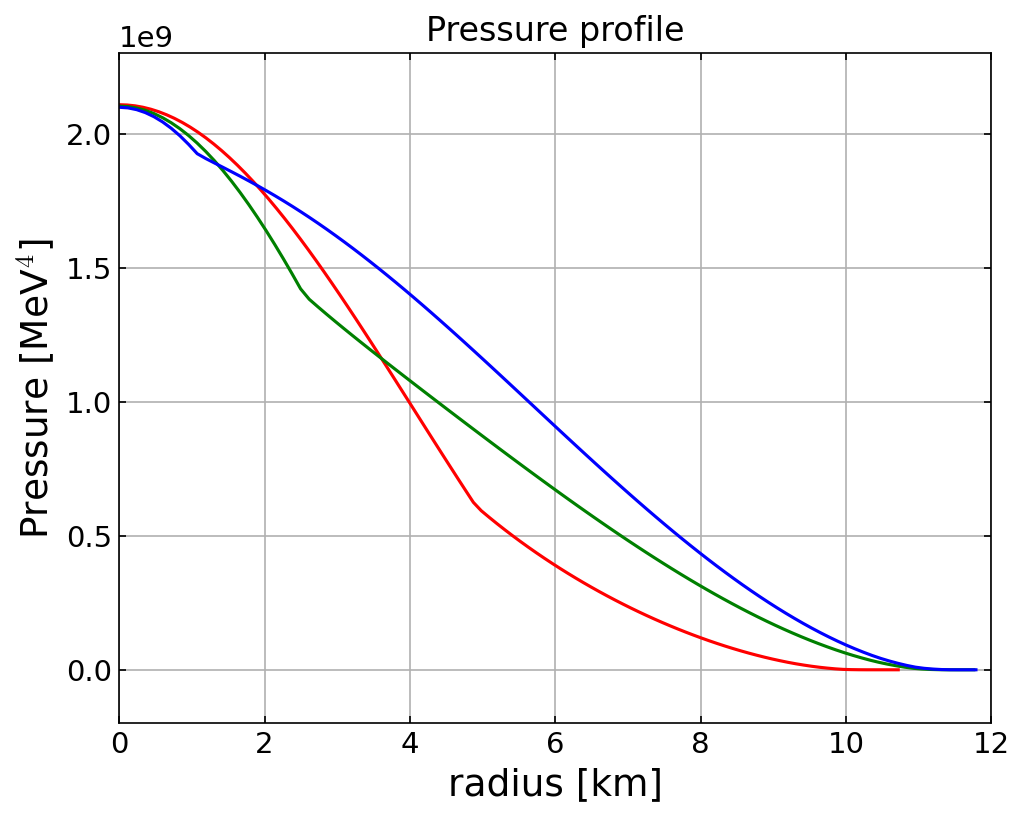

In [75]:
plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

plt.plot(r_test1, P_test1, 'r')
plt.plot(r_test2, P_test2, 'g')
plt.plot(r_test3, P_test3, 'b')

#plt.scatter(6.1, P_of_r(6.1), marker="*", c='r', s=100)
#plt.text(6.2, P_of_r(6.1)*1.1, rf"Critical", fontsize=16)
#plt.plot(radius, pressure, 'b')

plt.title("Pressure profile", fontsize = 16)
plt.xlabel(rf"radius [km]", fontsize = 18)
plt.ylabel(rf"Pressure [MeV$^4$]", fontsize = 18)

plt.xlim(0, 12)
plt.ylim(-0.2e+9, 2.3e+9)
plt.tick_params(which='both', direction='in', top=True, right=True)

plt.grid()
plt.show()

In [29]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, Get_Delta_P_max, _find_muB_muK_star

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

T = 15
n_kink1 = 2.5 * n0
n_kink2 = 4.0 * n0
n_kink3 = 4.5 * n0
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"


# solve for bag constant
P_kink1 = PNM_n(n_kink1, T)
P_kink2 = PNM_n(n_kink2, T)
P_kink3 = PNM_n(n_kink3, T)

### test run for $T = 15$ MeV

In [7]:
len(pressure1), len(radius1)

(907762, 907762)

In [14]:
type(pressure1), radius1

(numpy.ndarray,
 array([1.00000e-05, 2.00000e-05, 3.00000e-05, ..., 9.07760e+00,
        9.07761e+00, 9.07762e+00], shape=(907762,)))

In [24]:
from scipy.integrate import solve_ivp

Pressure_arr = pressure1
radius_arr = radius1
P_kink = P_kink1
T = 50
Interp1d_Num = 10
t_up=40
ms=0
paraa = para.paraQMCRMF3
NM_ty = "PNM"
aQmax=True

# 0) Safety: interpolation needs increasing x
#order = np.argsort(radius_arr)
#radius_arr = np.asarray(radius_arr, float)[order]
#Pressure_arr = np.asarray(Pressure_arr, float)[order]

# 1) P(r) and locate r_crit from P(r)=P_c
P_of_r = interp1d(np.array(radius_arr), np.array(Pressure_arr), kind="linear", fill_value="extrapolate")
r_kink = float(fsolve(lambda r: P_of_r(r) - P_kink, x0=3.0)[0])

# 2) calculate P_critical. We define it to be whatever pressure 1km away from the kink
z0 = 0.9  # km
P_c = P_of_r(r_kink + z0)
DelP_max = P_kink - P_c

# 3) Pre-tabulate v(z) on [0, z0] and build cheap interpolant
Interp1d_Num = max(int(Interp1d_Num), 2)  # need at least 2 points
z_list = np.linspace(0.0, z0, Interp1d_Num)

def vz_accurate(z):
    # z can be scalar or array; ensure scalar use here
    z = float(np.asarray(z).reshape(()))
    DelP_P_c = P_of_r(r_kink+z0 - z)
    vel, _ = vNtoQ_Pc(T=T, P_crit=P_c, DelP=float(DelP_P_c) - P_c,
                      m_s=ms, param=paraa, NM_type=NM_ty, aQmax=aQmax)
    return float(vel) / 1e3  # km/s

v_list = np.array([vz_accurate(z) for z in z_list], dtype=float)

# Use linear (more stable with few points). Keep cubic only if you have enough points & smoothness
vz_interp1d = interp1d(z_list, v_list, kind="linear", fill_value="extrapolate")

# 4) ODE: dz/dt = -v(z). Must accept y as 1-D array and return 1-D array
def dzdt(t, y):
    z = float(y[0])
    v = float(vz_interp1d(z))
    return np.array([-v], dtype=float)

# Stop when z hits 0
def hit_z_target(t, y, z_target=0.0):
    return y[0] - z_target

hit_z_target.terminal = True
hit_z_target.direction = 0

t0, t1 = 0.0, float(t_up)
t_eval = np.linspace(t0, t1, 500)

# y0 must be 1-D:
y0 = np.array([z0], dtype=float)

try:
    sol = solve_ivp(
        dzdt, (t0, t1), y0,
        method="RK45",
        t_eval=t_eval,
        events=lambda t, y: hit_z_target(t, y, z_target=0.0),
        rtol=1e-7, atol=1e-9
    )
except Exception as e:
    raise RuntimeError(f"solve_ivp failed with error: {e}") from e

if not sol.success:
    raise RuntimeError(f"Integration failed: {sol.message}")

# Return arrays directly
t = np.array(sol.t, dtype=float)                   # shape (M,)
z = np.array(sol.y[0], dtype=float)                # shape (M,)

n_crit = fsolve(lambda x: PNM_n(x, 15) - P_c, x0=3.0)[0]

In [21]:
n_crit/n0

np.float64(1.823349822022427)

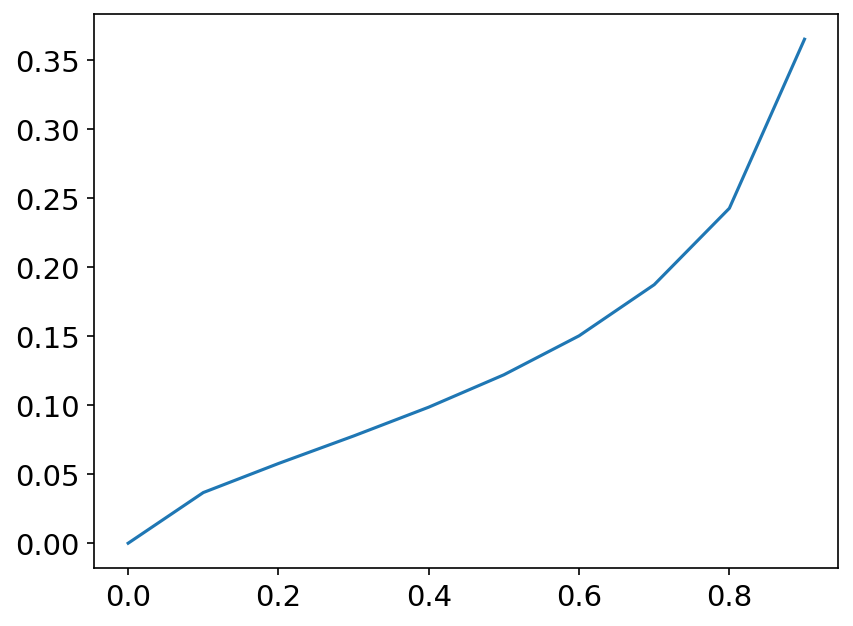

In [70]:
plt.plot(z_list, v_list)

In [56]:
from RMFsolver.phase_velocity import z_time_evolution1

tt, zz, P_crit = z_time_evolution1(
    Pressure_arr = pressure1, 
    radius_arr = radius1,
    P_kink = P_kink1,
    T = 50, 
    Interp1d_Num = 20,
    t_up = 100,
)

n_crit = fsolve(lambda x: PNM_n(x, 15) - P_crit, x0=3.0)[0]

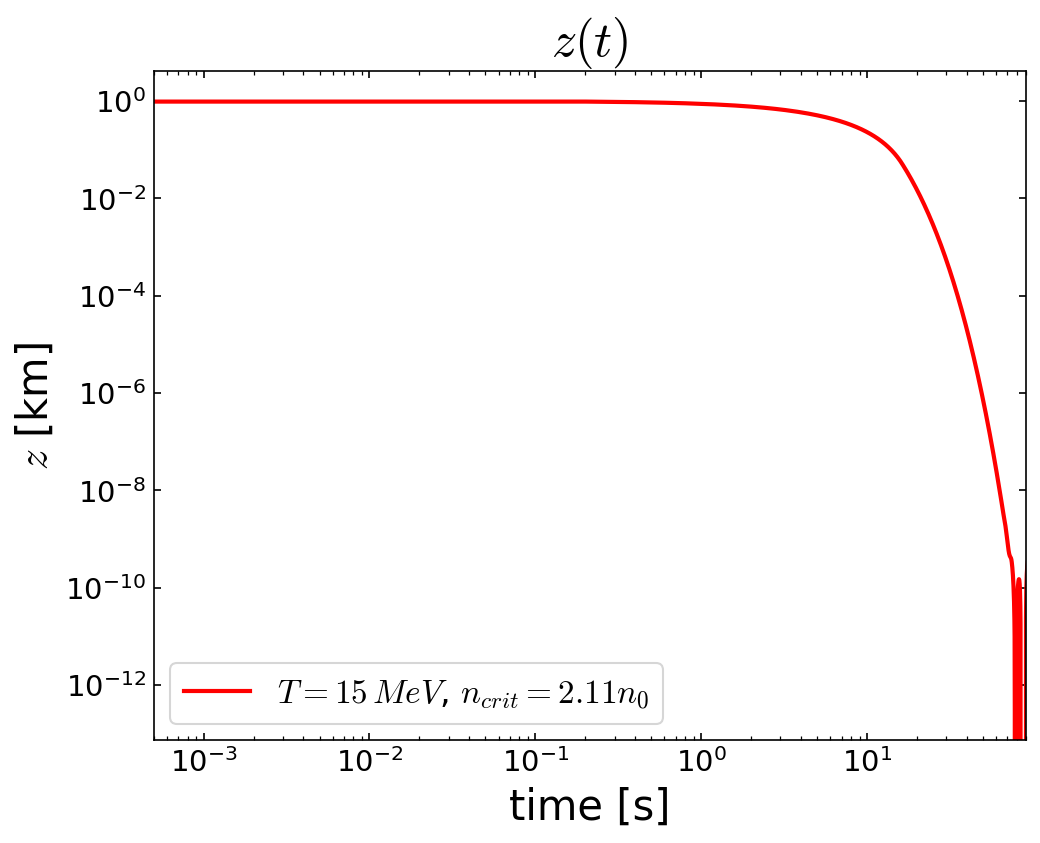

In [67]:
plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

t_upp = 90

plt.plot(tt, zz, lw=2, c='r', label = rf"$T=15\,MeV$, $n_{{crit}} = {n_crit/n0:.2f}n_0$")
plt.plot(np.linspace(0,t_upp,100), np.zeros(100), 'k', lw=1)
plt.xlim(5e-4, t_upp)
#plt.ylim(-0.3, 1.2)
plt.title(rf"$z(t)$", fontsize=24)
plt.xlabel(rf"time [s]", fontsize=20)
plt.ylabel(rf"$z$ [km]", fontsize=20)
plt.xscale("log")
plt.yscale("log")
#plt.xticks(np.array([1e-3, 1e-2, 1e-1, 1, 10, 20])*1e3)
plt.legend(fontsize=16)
plt.tick_params(which='both', direction='in', top=True, right=True)

#plt.savefig("z(t)_T15_nc2.5.pdf")

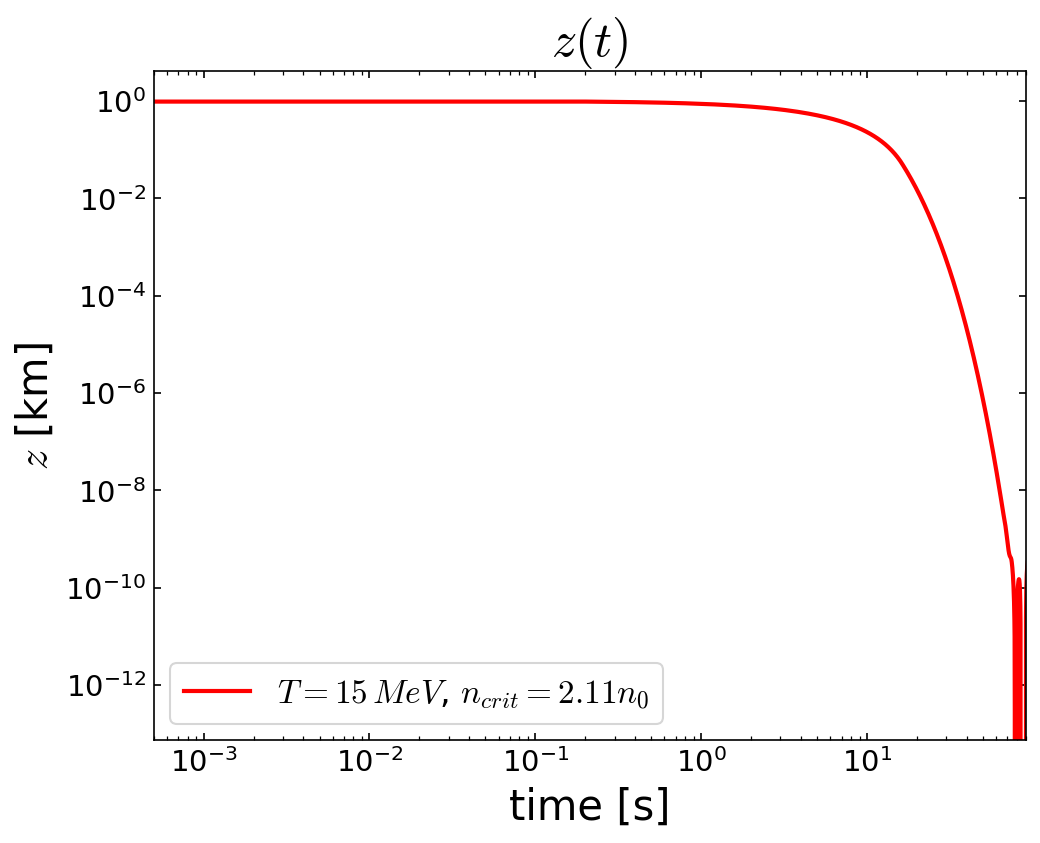

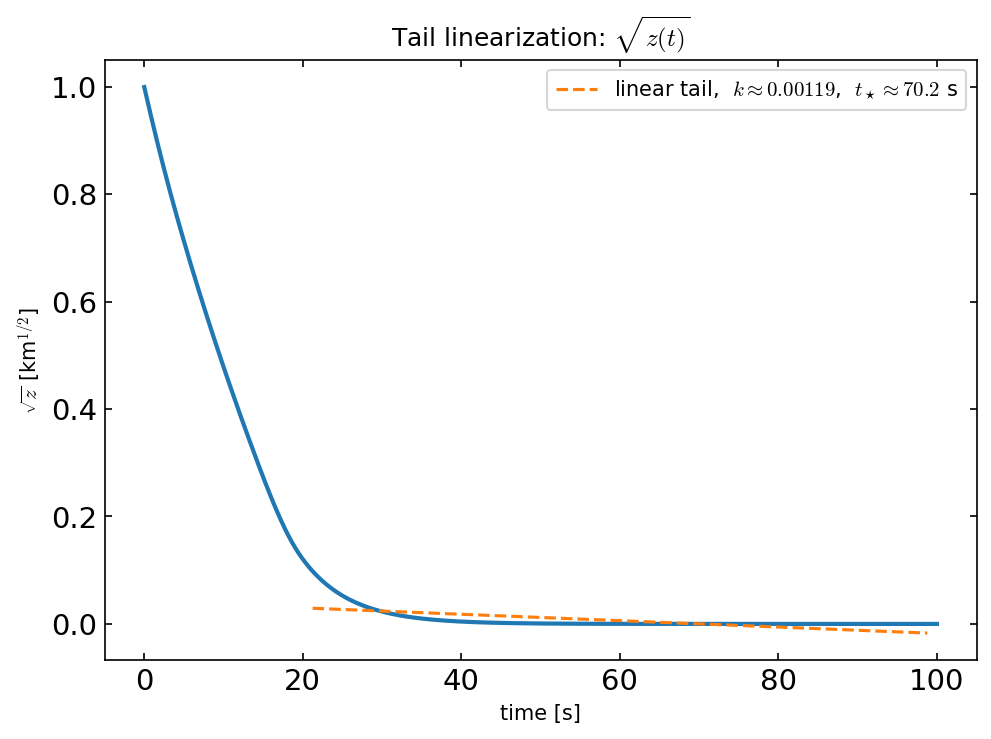

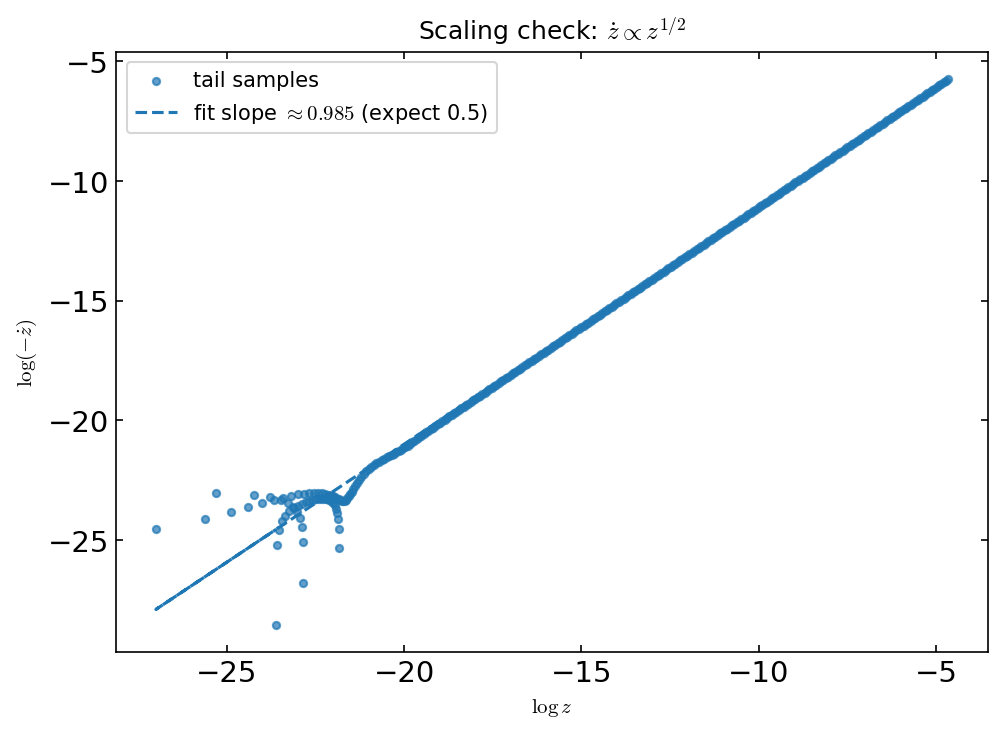

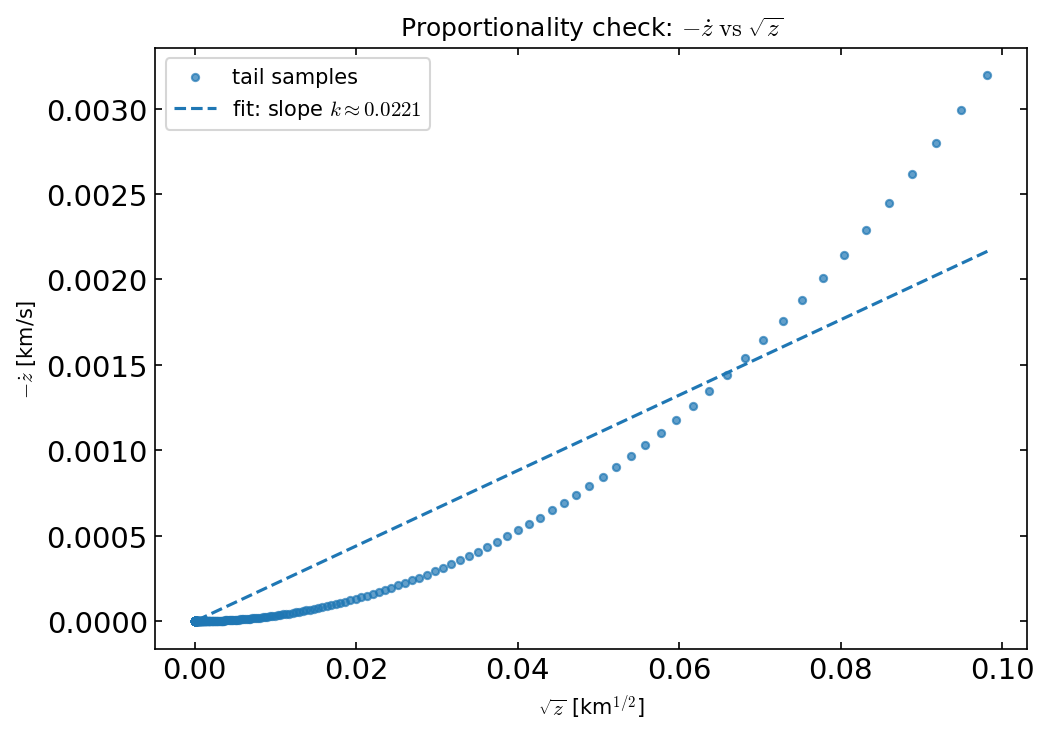

In [148]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# -------------------- your original figure --------------------
plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

t_upp = 90

plt.plot(tt, zz, lw=2, c='r', label = rf"$T=15\,MeV$, $n_{{crit}} = {n_crit/n0:.2f}n_0$")
plt.plot(np.linspace(0,t_upp,100), np.zeros(100), 'k', lw=1)
plt.xlim(5e-4, t_upp)
plt.title(rf"$z(t)$", fontsize=24)
plt.xlabel(rf"time [s]", fontsize=20)
plt.ylabel(rf"$z$ [km]", fontsize=20)
plt.xscale("log")
plt.yscale("log")
plt.legend(fontsize=16)
plt.tick_params(which='both', direction='in', top=True, right=True)
# plt.savefig("z(t)_T15_nc2.5.pdf")

# -------------------- diagnostics --------------------
# Smooth z(t) and compute dz/dt robustly
def _odd_window(n):
    # choose a reasonable odd window length between 5 and 101
    n = max(5, min(101, n))
    return n if n % 2 else n-1

win = _odd_window(max(5, len(zz)//25*2+1))  # ~4% of series length, odd
z_smooth = savgol_filter(zz, window_length=win, polyorder=3, mode='interp')
dzdt = np.gradient(z_smooth, tt)

# Tail window where the theory should apply: small-but-positive z
z_floor = max(1e-14, np.finfo(float).eps)
z_high  = 1e-2   # adjust if needed (km)
mask_tail = (z_smooth > z_floor) & (z_smooth < z_high) & (-dzdt > 0)

t_tail   = tt[mask_tail]
z_tail   = z_smooth[mask_tail]
dzdt_tail = dzdt[mask_tail]

# --- (1) sqrt(z) vs t -> linear fit near touchdown ---
plt.figure(figsize=[7.5, 5.2])
plt.plot(tt, np.sqrt(np.clip(z_smooth, 0, None)), lw=2)
if t_tail.size >= 5:
    y = np.sqrt(z_tail)
    coef = np.polyfit(t_tail, y, 1)       # y ≈ a t + b
    a, b = coef
    k_est = -2*a                          # since 2√z = -k t + C
    t_star = -b/a if a != 0 else np.nan   # intercept where √z -> 0
    plt.plot(t_tail, a*t_tail + b, '--', label=rf"linear tail,  $k\approx{ k_est:.3g}$,  $t_\star\approx{t_star:.3g}$ s")
plt.xlabel("time [s]"); plt.ylabel(r"$\sqrt{z}$ [km$^{1/2}$]")
plt.title(r"Tail linearization: $\sqrt{z(t)}$")
plt.legend()
plt.tick_params(which='both', direction='in', top=True, right=True)

# --- (2) log(-dz/dt) vs log z -> slope ~ 1/2 ---
plt.figure(figsize=[7.5, 5.2])
x = np.log(z_tail)
y = np.log(-dzdt_tail)
plt.scatter(x, y, s=12, alpha=0.7, label="tail samples")
if x.size >= 5:
    m, c = np.polyfit(x, y, 1)            # y ≈ m x + c
    plt.plot(x, m*x + c, '--', label=rf"fit slope $\approx {m:.3f}$ (expect 0.5)")
plt.xlabel(r"$\log z$")
plt.ylabel(r"$\log(-\dot z)$")
plt.title(r"Scaling check: $\dot z \propto z^{1/2}$")
plt.legend()
plt.tick_params(which='both', direction='in', top=True, right=True)

# --- (3) -dz/dt vs sqrt(z) -> straight line through origin ---
plt.figure(figsize=[7.5, 5.2])
xs = np.sqrt(z_tail)
ys = -dzdt_tail
plt.scatter(xs, ys, s=12, alpha=0.7, label="tail samples")
if xs.size >= 5:
    # linear fit constrained to pass through origin: slope = (x·y)/(x·x)
    slope = np.dot(xs, ys)/np.dot(xs, xs)
    plt.plot(xs, slope*xs, '--', label=rf"fit: slope $k\approx {slope:.3g}$")
plt.xlabel(r"$\sqrt{z}$ [km$^{1/2}$]")
plt.ylabel(r"$-\dot z$ [km/s]")
plt.title(r"Proportionality check: $-\dot z \; \text{vs} \; \sqrt{z}$")
plt.legend()
plt.tick_params(which='both', direction='in', top=True, right=True)

In [41]:
from RMFsolver.phase_velocity import z_time_evolution1

Temp_list = [0.1, 1, 10, 50]

t1 = []
z1 = []
t2 = []
z2 = []
t3 = []
z3 = []
P_cr1 = []
P_cr2 = []
P_cr3 = []

time_up = 100

for Te in Temp_list:
    tt1, zz1, P_crit1 = z_time_evolution1(
        Pressure_arr = pressure1, 
        radius_arr = radius1,
        P_kink = P_kink1,
        T = Te, 
        Interp1d_Num = 10,
        t_up = time_up,
    )
    
    tt2, zz2, P_crit2 = z_time_evolution1(
        Pressure_arr = pressure2, 
        radius_arr = radius2,
        P_kink = P_kink2,
        T = Te, 
        Interp1d_Num = 10,
        t_up = time_up,
    )
    
    tt3, zz3, P_crit3 = z_time_evolution1(
        Pressure_arr = pressure3, 
        radius_arr = radius3,
        P_kink = P_kink3,
        T = Te, 
        Interp1d_Num = 10,
        t_up = time_up,
    )

    t1.append(tt1)
    z1.append(zz1)
    
    t2.append(tt2)
    z2.append(zz2)

    t3.append(tt3)
    z3.append(zz3)

    P_cr1.append(P_crit1)
    P_cr2.append(P_crit2)
    P_cr3.append(P_crit3)
    
    print(Te)

0.1
1
10
50


In [43]:
n_cr1 = []
n_cr2 = []
n_cr3 = []

for i in range(len(Temp_list)):
    
    n_crit1 = fsolve(lambda x: PNM_n(x, Temp_list[i]) - P_cr1[i], x0=3.0*n0)[0]
    n_crit2 = fsolve(lambda x: PNM_n(x, Temp_list[i]) - P_cr2[i], x0=3.0*n0)[0]
    n_crit3 = fsolve(lambda x: PNM_n(x, Temp_list[i]) - P_cr3[i], x0=3.0*n0)[0]

    n_cr1.append(n_crit1)
    n_cr2.append(n_crit2)
    n_cr3.append(n_crit3)

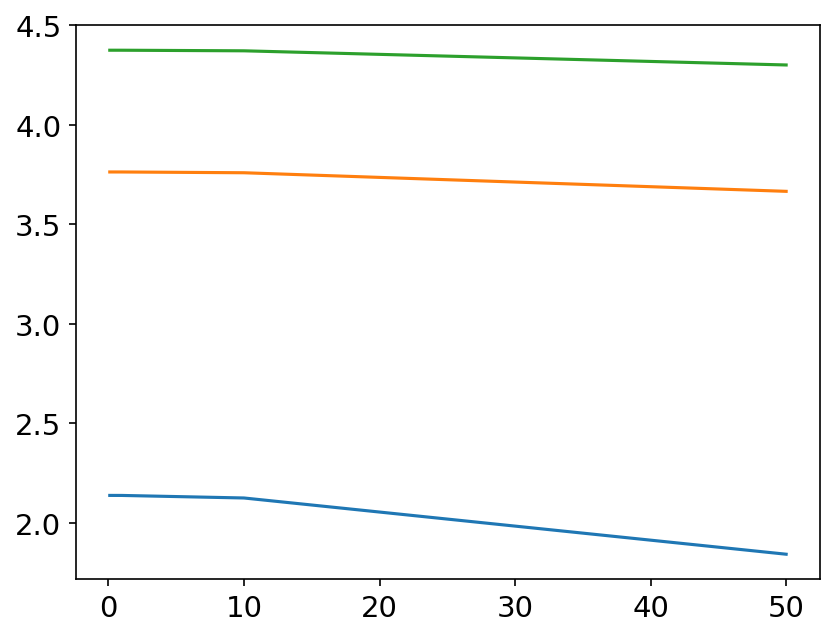

In [46]:
plt.plot(Temp_list, np.array(n_cr1)/n0)
plt.plot(Temp_list, np.array(n_cr2)/n0)
plt.plot(Temp_list, np.array(n_cr3)/n0)

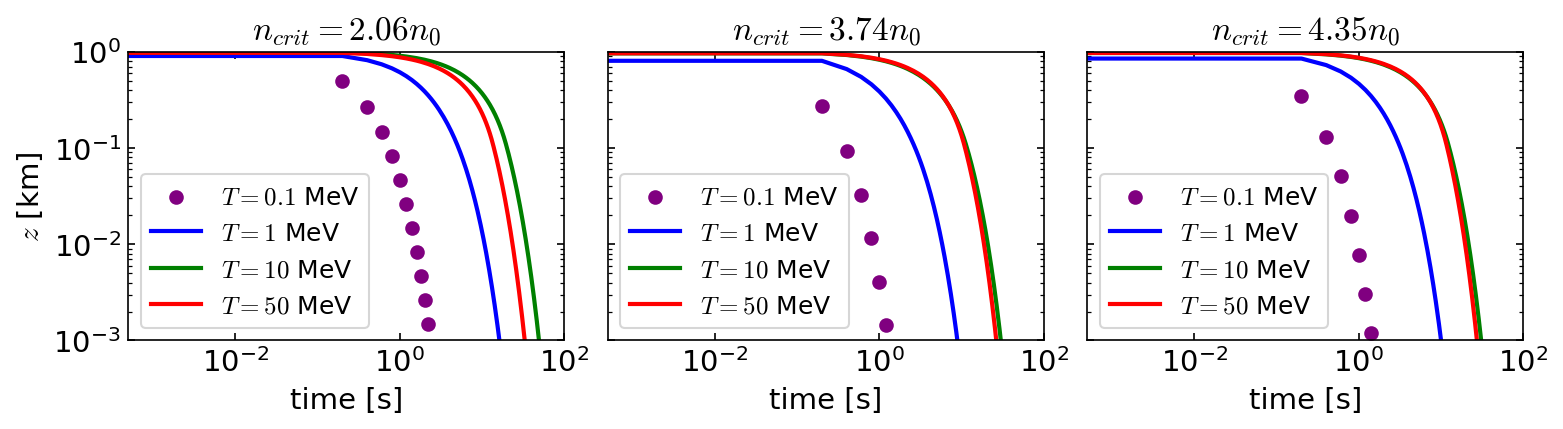

In [121]:
import matplotlib as mpl
fig, axs = plt.subplots(1, 3, figsize=(12, 2.5), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.1, hspace=0.05)

mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
})

t_upp = 100

axs[0].scatter(t1[0], z1[0], c='purple', label = rf"$T=0.1$ MeV")
axs[0].plot(t1[1], z1[1], lw=2, c='b', label = rf"$T=1$ MeV")
axs[0].plot(t1[2], z1[2], lw=2, c='g', label = rf"$T=10$ MeV")
axs[0].plot(t1[3], z1[3], lw=2, c='r', label = rf"$T=50$ MeV")
axs[0].plot(np.linspace(0,t_upp,100), np.zeros(100), 'k', lw=1)
axs[0].set_xlim(5e-4, t_upp)
axs[0].set_ylim(1e-3, 1.2)
axs[0].set_title(rf"$n_{{crit}} = {np.mean(n_cr1)/n0:.2f}n_0$", fontsize=16)
axs[0].set_xlabel(rf"time [s]", fontsize=14)
axs[0].set_ylabel(rf"$z$ [km]", fontsize=14)
axs[0].set_yscale("log")
axs[0].set_xscale("log")
axs[0].set_ylim(1e-3, 1)
axs[0].legend(fontsize=12)
axs[0].tick_params(which='both', direction='in', top=True, right=True)

axs[1].scatter(t2[0], z2[0], c='purple', label = rf"$T=0.1$ MeV")
axs[1].plot(t2[1], z2[1], lw=2, c='b', label = rf"$T=1$ MeV")
axs[1].plot(t2[2], z2[2], lw=2, c='g', label = rf"$T=10$ MeV")
axs[1].plot(t2[3], z2[3], lw=2, c='r', label = rf"$T=50$ MeV")
axs[1].plot(np.linspace(0,t_upp,100), np.zeros(100), 'k', lw=1)
axs[1].set_xlim(5e-4, t_upp)
axs[1].set_ylim(1e-3, 1.2)
axs[1].set_title(rf"$n_{{crit}} = {np.mean(n_cr2)/n0:.2f}n_0$", fontsize=16)
axs[1].set_xlabel(rf"time [s]", fontsize=14)
#axs[1].set_ylabel(rf"$z$ [km]", fontsize=14)
axs[1].set_yscale("log")
axs[1].set_xscale("log")
axs[0].set_ylim(1e-3, 1)
axs[1].legend(fontsize=12)
axs[1].tick_params(which='both', direction='in', top=True, right=True)

axs[2].scatter(t3[0], z3[0], c='purple', label = rf"$T=0.1$ MeV")
axs[2].plot(t3[1], z3[1], lw=2, c='b', label = rf"$T=1$ MeV")
axs[2].plot(t3[2], z3[2], lw=2, c='g', label = rf"$T=10$ MeV")
axs[2].plot(t3[3], z3[3], lw=2, c='r', label = rf"$T=50$ MeV")
axs[2].plot(np.linspace(0,t_upp,100), np.zeros(100), 'k', lw=1)
axs[2].set_xlim(5e-4, t_upp)
axs[2].set_ylim(1e-3, 1.2)
axs[2].set_title(rf"$n_{{crit}} = {np.mean(n_cr3)/n0:.2f}n_0$", fontsize=16)
axs[2].set_xlabel(rf"time [s]", fontsize=14)
#axs[2].set_ylabel(rf"$z$ [km]", fontsize=14)
axs[2].set_yscale("log")
axs[2].set_xscale("log")
axs[0].set_ylim(1e-3, 1)
axs[2].legend(fontsize=12)
axs[2].tick_params(which='both', direction='in', top=True, right=True)

#plt.savefig("Various_z(t)_new_idea_log.pdf", bbox_inches="tight")

* for $T = 0$, do the "2x2" contour to see if at zero temperature velocity
* change the 2x2 plot to 1x3
* start writing 

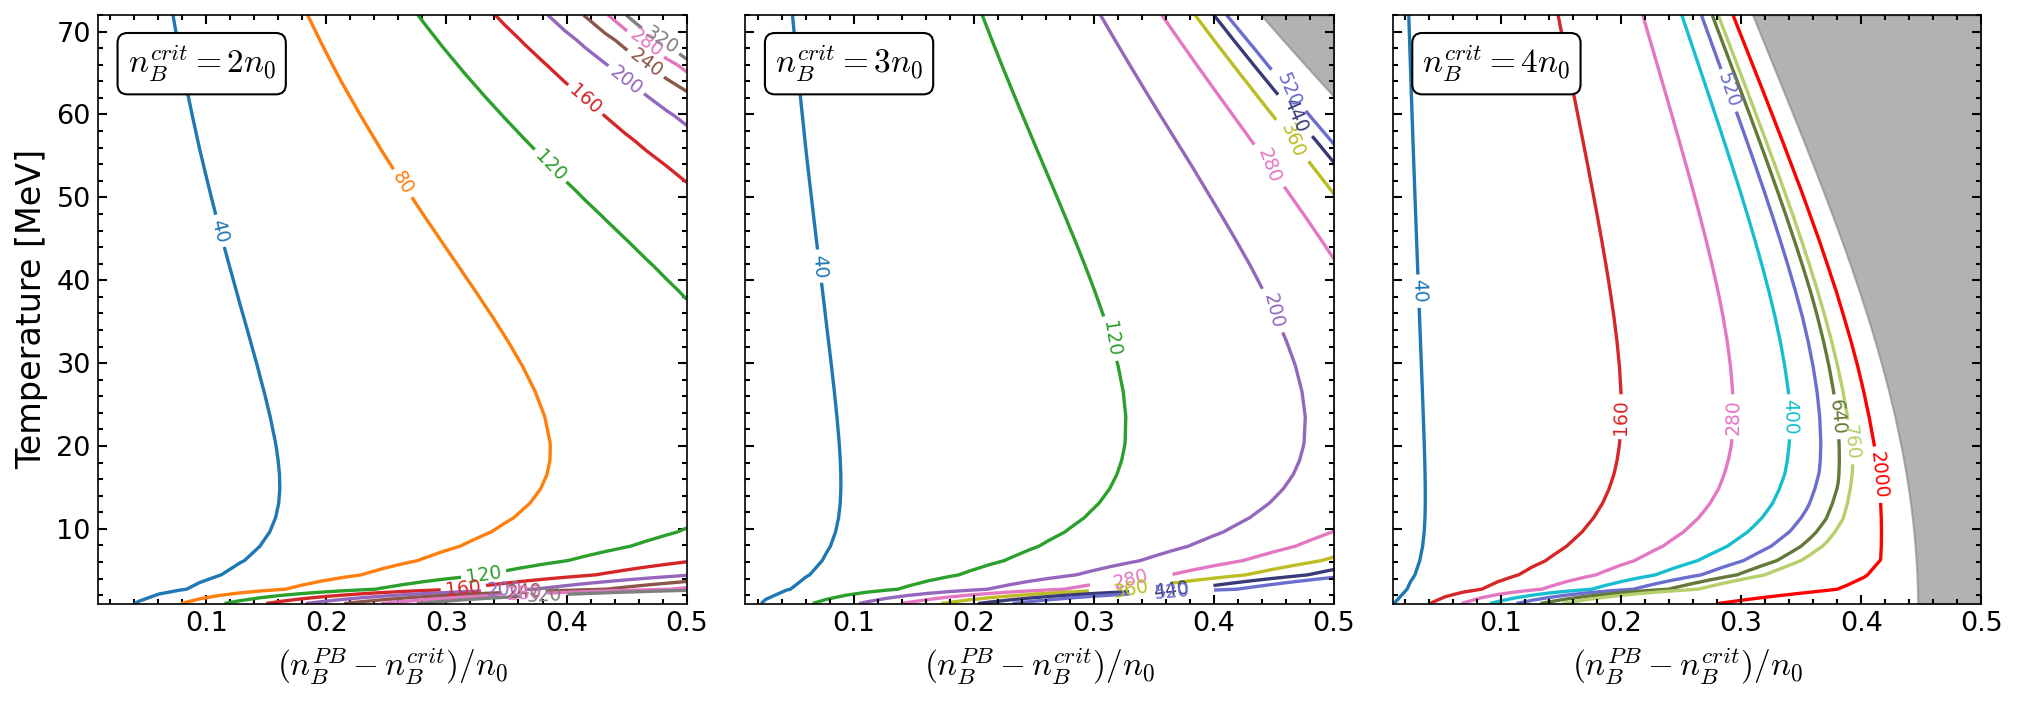

In [126]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM
import matplotlib.colors as mcolors

# Define n0 (adjust as needed)
n0 = 0.16 * const.MeV_fm**3

nc2, nc3, nc4, nc5 = 2*n0, 3*n0, 4*n0, 4.5*n0
N = 30
path = "/Users/janshao/NSM_related/v_0.002n0/"
path_safe = "/Users/janshao/NSM_related/v_0.015n0_safe/"

al = 0.6

# shaded region
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3.0.npy")
Cut3 = interp1d(T_cut3, Deln_cut3, kind='linear', fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load("Shade_n_crit=4.0.npy")
Cut4 = interp1d(T_cut4, Deln_cut4, kind='linear', fill_value="extrapolate")

Deln_cut4_5, T_cut4_5 = np.load("Shade_n_crit=4.5.npy")
Cut4_5 = interp1d(T_cut4_5, Deln_cut4_5, kind='linear', fill_value="extrapolate")

# ------------------------------------------------------------------------------------
# Levels per subplot
# ------------------------------------------------------------------------------------
levels_11 = np.concatenate([[40+40*i for i in range(8)]])               # 8 levels (2 n0)
levels_12 = np.concatenate([[40+80*i for i in range(7)]])               # 7 levels (3 n0)
levels_21 = np.concatenate([[40+120*i for i in range(7)], [2000]])      # + special 2000 (4 n0)

# Global set of all levels remaining
ALL_LEVELS = np.unique(np.concatenate([levels_11, levels_12, levels_21]))

# ------------------- COLOR MAPPING -------------------
'''
SPECIAL_LEVELS = {2000, 3000}
NORMAL_LEVELS = np.array(sorted([l for l in ALL_LEVELS if l not in SPECIAL_LEVELS]))

cmap = plt.get_cmap('tab20') #copper, winter, tab10, Dark2
norm = mcolors.PowerNorm(gamma=0.8, vmin=NORMAL_LEVELS.min(), vmax=NORMAL_LEVELS.max())

LEVEL_COLOR = {
    lev: (1.0, 0.0, 0.0, 1.0) if lev in SPECIAL_LEVELS else cmap(norm(lev))
    for lev in ALL_LEVELS
}
'''
from matplotlib.colors import ListedColormap

tab20 = plt.get_cmap("tab20").colors
sat = [tab20[i] for i in [0,2,4,6,8,10,12,14,16,18]]  # saturated rows only
tab20b = plt.get_cmap("tab20b").colors
tab20c = plt.get_cmap("tab20c").colors
palette = sat + list(tab20b[::2]) + list(tab20c[::2])  # stitch bright colors

cmap = ListedColormap(palette, name="tab20_bright")
def pick(i): return cmap.colors[i % len(cmap.colors)]

LEVEL_COLOR = {lev: pick(k) for k, lev in enumerate(all_levels)}
for s in (2000, 3000): LEVEL_COLOR[s] = (1,0,0,1)


def contour_with_fixed_colors(ax, X, Y, Z, levels, **kwargs):
    cols = [LEVEL_COLOR[lev] for lev in levels]
    cs = ax.contour(X, Y, Z, levels=levels, colors=cols, **kwargs)
    ax.clabel(cs, inline=True, fontsize=9, fmt="%d")  # ↑ larger labels
    return cs

# ================= 1 x 3 LAYOUT (square subplots) =================
fig, axs = plt.subplots(1, 3, figsize=(13.5, 4.8), sharey=True)
plt.subplots_adjust(left=0.05, right=0.98, bottom=0.12, top=0.95, wspace=0.10)
for ax in axs:
    ax.set_box_aspect(1)  # make each axes square

ax20, ax30, ax40 = axs  # 2n0, 3n0, 4n0

# Common T grid
TT = np.hstack([np.linspace(1, 20, int(N*2/5)), np.linspace(20.5, 72, int(N*3/5))])

# ------------------ panel 1: n_crit = 2 n0 ------------------
D2 = np.linspace(0.01*n0, 0.5*n0, N)
V2 = np.load(path+"v_n_crit=2.0.npy")
X20, Y20 = np.meshgrid(D2/n0, TT)
contour_with_fixed_colors(ax20, X20, Y20, V2, levels_11, linewidths=1.6)
ax20.annotate(r"$n_B^{crit} = 2 n_0$", xy=(0.05, 0.90), xycoords='axes fraction',
              fontsize=16, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ panel 2: n_crit = 3 n0 ------------------
V3  = np.load(path_safe+"v_n_crit=3.0.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut3(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut3(TT)
ax30.fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(ax30, D_grid/n0, T_grid, V3, levels_12, linewidths=1.6, zorder=1)
ax30.set_xlim(0.01, 0.5)
ax30.set_ylim(1, 72)
ax30.annotate(r"$n_B^{crit} = 3 n_0$", xy=(0.05, 0.90), xycoords='axes fraction',
              fontsize=16, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ------------------ panel 3: n_crit = 4 n0 ------------------
V4  = np.load(path+"v_n_crit=4.0.npy")
t   = np.linspace(0.0, 1.0, N)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4(TT) - 0.015 * n0)
Dmax = np.maximum(Dmax, Dlo)
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]
T_grid = np.repeat(TT[:, None], N, axis=1)

Dcut = Cut4(TT)
ax40.fill_betweenx(TT, Dcut/n0, (0.5*n0)/n0, color="grey", alpha=al, zorder=0)

contour_with_fixed_colors(ax40, D_grid/n0, T_grid, V4, levels_21, linewidths=1.6, zorder=1)
ax40.set_xlim(0.01, 0.5)
ax40.set_ylim(1, 72)
ax40.annotate(r"$n_B^{crit} = 4 n_0$", xy=(0.05, 0.90), xycoords='axes fraction',
              fontsize=16, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

# ---------- axes labels & ticks ----------
ax20.set_ylabel("Temperature [MeV]", fontsize=16)
for ax in (ax20, ax30, ax40):
    ax.set_xlabel(r"$(n^{PB}_B - n^{crit}_B) / n_0$", fontsize=16)
    ax.minorticks_on()
    ax.tick_params(which='both', direction='in', top=True, right=True,
                   length=4.5, width=1.0, labelsize=13)
    ax.tick_params(which='minor', length=2.5)
    #ax.set_yscale("log")

plt.savefig("1by3_Grid.pdf")
# plt.show()